# Rocha — DeepForest y Mask R-CNN

## 1. Preparación compartida

In [1]:
%pip -q install deepforest rasterio ultralytics geopandas pyogrio shapely matplotlib pandas tqdm scipy

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.42.1 requires safetensors>=0.8.0, but you have safetensors 0.5.3 which is incompatible.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from rasterio.windows import Window
from rasterio.enums import ColorInterp, Resampling, MaskFlags
from rasterio.features import rasterize, shapes
from shapely.geometry import box, shape
from matplotlib.lines import Line2D
from tqdm.auto import tqdm

SITIO = 'Rocha'
PROYECTO = Path('/content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto')
ROOT = PROYECTO / 'PruebaFinal'
DATOS = ROOT / 'datos'
RASTER = DATOS / 'Rocha_20240222_censo_clip.tif'
CENSO = DATOS / 'Censo_Rocha_parcelas_15-16.shp'
PREDIO = None

print("Predio:", SITIO)
print("Ortofoto:", RASTER)
print("Censo:", CENSO)
# Archivos compartidos por ambos modelos.
SALIDA_COMUN = ROOT / 'resultados' / 'Rocha' / 'compartido'
SALIDA_COMUN.mkdir(parents=True, exist_ok=True)
MASCARA_COMUN = SALIDA_COMUN / 'mascara_evaluable.tif'


Predio: Rocha
Ortofoto: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/datos/Rocha_20240222_censo_clip.tif
Censo: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/datos/Censo_Rocha_parcelas_15-16.shp


## 2. Máscara y censo evaluable

La misma área evaluable se utiliza para los dos modelos.

In [6]:
MASCARA = MASCARA_COMUN
# Construir la máscara de cobertura válida y seleccionar el censo evaluable.
with rasterio.open(RASTER) as src:
    assert src.crs is not None and src.count >= 3
    alpha_bands = [i+1 for i, ci in enumerate(src.colorinterp) if ci == ColorInterp.alpha]
    has_nodata = src.nodata is not None
    if SITIO == 'Rocha':
        assert alpha_bands, 'Revisar bandas del TIFF.'
    elif not alpha_bands and not has_nodata:
        flags = src.mask_flag_enums[0]
        assert MaskFlags.all_valid not in flags, ('Revisar el TIFF')

    if PREDIO is not None:
        area = gpd.read_file(PREDIO)
        area = area.to_crs(src.crs)
        zona = area.geometry.union_all()
        print('Área estimada del predio (ha):', round(zona.area/10000, 2))
    else:
        zona = None

    perfil = src.profile.copy()
    perfil.update(driver='GTiff', count=1, dtype='uint8', nodata=0, compress='deflate')
    valid_pixels = 0
    with rasterio.open(MASCARA_COMUN, 'w', **perfil) as dst:
        for _, win in tqdm(src.block_windows(1), desc='Creando máscara'):
            h,w = int(win.height),int(win.width)
            if zona is not None:
                zona_pixel = rasterize([(zona,1)],out_shape=(h,w),transform=src.window_transform(win),
                                       fill=0,dtype='uint8').astype(bool)
                if not zona_pixel.any():
                    dst.write(np.zeros((h,w),dtype='uint8'), 1, window=win)
                    continue
            else:
                zona_pixel = np.ones((h,w),dtype=bool)
            if alpha_bands:
                cubierta = src.read(alpha_bands[0], window=win)>0
            elif has_nodata:
                rgb = src.read([1,2,3],window=win).astype('float32')
                cubierta = np.all(~np.isclose(rgb,src.nodata),axis=0)
            else:
                cubierta = src.read_masks(1,window=win)>0
            v = (cubierta & zona_pixel).astype('uint8')
            valid_pixels += int(v.sum())
            dst.write(v, 1, window=win)
    print('Cobertura válida en máscara (% del raster):',round(100*valid_pixels/(src.width*src.height),2))


def puntos_mascara(geoms, ruta):
    with rasterio.open(ruta) as m:
        result=[]
        for g in geoms:
            if g is None or g.is_empty:
                result.append(False);continue
            try: result.append(bool(next(m.sample([(g.x,g.y)]))[0] == 1))
            except Exception: result.append(False)
        return np.asarray(result,dtype=bool)

censo_total = gpd.read_file(CENSO).reset_index(drop=True)
assert censo_total.crs is not None
with rasterio.open(MASCARA_COMUN) as m:
    censo_total = censo_total.to_crs(m.crs)
censo_eval = censo_total.loc[puntos_mascara(censo_total.geometry,MASCARA_COMUN)].copy().reset_index(drop=True)
censo_eval['id_punto'] = np.arange(len(censo_eval))
assert len(censo_eval) > 0, 'No hay árboles evaluables: revisar CRS, censo y máscara.'
print('Censo total:',len(censo_total),'| Censo evaluable:',len(censo_eval),
      '| Excluidos:',len(censo_total)-len(censo_eval))

Creando máscara: 0it [00:00, ?it/s]

Cobertura válida en máscara (% del raster): 43.12
Censo total: 4844 | Censo evaluable: 4502 | Excluidos: 342


In [7]:
# Emparejamiento espacial 1:1 compartido por ambos modelos.
def evaluar_detecciones(pred_unicas, censo_eval, mascara):
    pred_eval = pred_unicas.to_crs(censo_eval.crs).copy().reset_index(drop=True)
    if len(pred_eval):
        dentro = puntos_mascara(pred_eval.geometry.centroid, mascara)
        pred_eval = pred_eval.loc[dentro].copy().reset_index(drop=True)
    pred_eval['id_pred'] = np.arange(len(pred_eval))
    ref = censo_eval.copy().reset_index(drop=True)

    if len(pred_eval):
        pares = gpd.sjoin(ref[['id_punto', 'geometry']],
                          pred_eval[['id_pred', 'geometry']],
                          how='inner', predicate='within')
    else:
        pares = pd.DataFrame(columns=['id_punto', 'id_pred'])

    coincidencias = []
    if len(pares):
        puntos = ref.set_index('id_punto').geometry
        centros = pred_eval.set_index('id_pred').geometry.centroid
        pares['distancia_m'] = [puntos.loc[int(i)].distance(centros.loc[int(j)])
                                for i, j in zip(pares.id_punto, pares.id_pred)]
        pares = pares.sort_values('distancia_m')
        usados_ref, usados_pred = set(), set()
        for fila in pares.itertuples():
            i, j = int(fila.id_punto), int(fila.id_pred)
            if i not in usados_ref and j not in usados_pred:
                usados_ref.add(i)
                usados_pred.add(j)
                coincidencias.append({'id_punto': i, 'id_pred': j,
                                      'distancia_m': float(fila.distancia_m)})

    TP = len(coincidencias)
    NR, NP = len(ref), len(pred_eval)
    FP, FN = NP - TP, NR - TP
    P = TP / NP if NP else 0.0
    R = TP / NR if NR else 0.0
    F1 = 2 * P * R / (P + R) if P + R else 0.0
    error = 100 * (NP - NR) / NR
    assert TP + FP == NP and TP + FN == NR
    metricas = dict(censo_total=len(censo_total), censo_evaluable=NR,
                    detecciones=NP, TP=TP, FP=FP, FN=FN, precision=P,
                    recall=R, F1=F1, error_conteo_pct=error,
                    error_absoluto_pct=abs(error))
    return ref, pred_eval, coincidencias, metricas


## 3. DeepForest

### Configuración

In [10]:
SALIDA = ROOT / 'resultados' / 'Rocha_DeepForest'
SALIDA.mkdir(parents=True, exist_ok=True)
MASCARA = MASCARA_COMUN
PREPARADA = SALIDA / 'rgb_uint8_global.tif'

PATCH_SIZE = 400
PATCH_OVERLAP = 0.30
SCORE_THRESHOLD = 0.15
IOU_THRESHOLD = 0.15

print('Sitio:', SITIO, '\nOrtofoto:', RASTER, '\nCenso:', CENSO, '\nSalida:', SALIDA)

Sitio: Rocha 
Ortofoto: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/datos/Rocha_20240222_censo_clip.tif 
Censo: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/datos/Censo_Rocha_parcelas_15-16.shp 
Salida: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/resultados/Rocha_DeepForest


### Preparación RGB e inferencia

In [11]:
from deepforest import main

# Muestrear píxeles para estimar el rango de intensidades sin cargar toda la imagen.
rng = np.random.default_rng(42)
values = []
with rasterio.open(RASTER) as src:
    alpha_bands = [i+1 for i,ci in enumerate(src.colorinterp) if ci == ColorInterp.alpha]
    for _, win in tqdm(src.block_windows(1), desc='Muestreando percentiles'):
        data = src.read([1,2,3],window=win).astype('float32')
        if alpha_bands:
            vv = src.read(alpha_bands[0],window=win)>0
        elif src.nodata is not None:
            vv = np.all(~np.isclose(data,src.nodata),axis=0)
        else:
            vv = src.read_masks(1,window=win)>0
        # muestra máx. 300 píxeles por bloque, repartida sobre la imagen
        locations = np.flatnonzero(vv.ravel())
        if locations.size:
            pick = rng.choice(locations,size=min(300,locations.size),replace=False)
            values.append(data.reshape(3,-1)[:,pick].reshape(-1))
assert values,'No hay píxeles válidos para calcular percentiles'
sample = np.concatenate(values)
p2 = float(np.percentile(sample,2))
p98 = float(np.percentile(sample,98))
del sample,values
assert np.isfinite(p2) and np.isfinite(p98) and p98>p2, 'Percentiles inválidos'
print('P2 muestreado:',p2,'P98 muestreado:',p98)

# Aplicar la misma escala a toda la imagen y anular los píxeles no evaluables.
with rasterio.open(RASTER) as src, rasterio.open(MASCARA) as msk:
    perfil = src.profile.copy()
    perfil.update(driver='GTiff',count=3,dtype='uint8',nodata=0,compress='deflate')
    with rasterio.open(PREPARADA,'w',**perfil) as dst:
        for _, win in tqdm(src.block_windows(1),desc='Preparando uint8'):
            data = src.read([1,2,3],window=win).astype('float32')
            valid = msk.read(1,window=win)>0
            rgb8=(np.clip((data-p2)/(p98-p2),0,1)*255).astype('uint8')
            rgb8[:,~valid]=0
            dst.write(rgb8,window=win)
print('RGB preparado:',PREPARADA)

# Cargar el modelo preentrenado y detectar árboles por teselas.
modelo_df = main.deepforest()
modelo_df.load_model(model_name='weecology/deepforest-tree')
pred_df = modelo_df.predict_tile(path=str(PREPARADA),patch_size=PATCH_SIZE,
                                patch_overlap=PATCH_OVERLAP,iou_threshold=IOU_THRESHOLD)
if pred_df is None or len(pred_df)==0:
    pred_df = pd.DataFrame(columns=['xmin','ymin','xmax','ymax','score'])
else:
    pred_df = pred_df.loc[pred_df['score']>=SCORE_THRESHOLD].copy().reset_index(drop=True)
print('Cajas tras score y NMS interno:',len(pred_df))

with rasterio.open(PREPARADA) as src:
    trans=src.transform
    crs=src.crs
# Transformar coordenadas de píxeles a coordenadas espaciales.
geoms=[]
for r in pred_df.itertuples():
    x1,y1=rasterio.transform.xy(trans,r.ymin,r.xmin,offset='ul')
    x2,y2=rasterio.transform.xy(trans,r.ymax,r.xmax,offset='ul')
    geoms.append(box(min(x1,x2),min(y1,y2),max(x1,x2),max(y1,y2)))
pred_brutas = gpd.GeoDataFrame(pred_df.copy(),geometry=geoms,crs=crs)
# DeepForest ya aplica la supresión de detecciones solapadas (NMS).
pred_unicas = pred_brutas.copy()

Muestreando percentiles: 0it [00:00, ?it/s]

P2 muestreado: 12.0 P98 muestreado: 220.0


Preparando uint8: 0it [00:00, ?it/s]

RGB preparado: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/resultados/Rocha_DeepForest/rgb_uint8_global.tif


config.json:   0%|          | 0.00/235 [00:00<?, ?B/s]

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


... (3 outputs left out)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


9734 predictions in overlapping windows, applying non-max suppression
4769 predictions kept after non-max suppression
Cajas tras score y NMS interno: 4647


### Evaluación

In [12]:
ref, pred_eval, coincidencias, metricas = evaluar_detecciones(pred_unicas, censo_eval, MASCARA)
NR, NP = metricas['censo_evaluable'], metricas['detecciones']
TP, FP, FN = metricas['TP'], metricas['FP'], metricas['FN']
resumen = pd.DataFrame([dict(sitio=SITIO, modelo='DeepForest', **metricas,
    patch_size=PATCH_SIZE, patch_overlap=PATCH_OVERLAP,
    score_threshold=SCORE_THRESHOLD, iou_threshold=IOU_THRESHOLD,
    p2_muestreado=p2, p98_muestreado=p98)])
resumen_deepforest = resumen.copy()
display(resumen.round(4))
resumen.to_csv(SALIDA / 'DeepForest_metricas_censales.csv', index=False)
pd.DataFrame(coincidencias, columns=['id_punto','id_pred','distancia_m']).to_csv(SALIDA / 'DeepForest_matches.csv', index=False)
ref.to_file(SALIDA / 'censo_evaluable.gpkg', driver='GPKG')
if len(pred_eval):
    pred_eval.to_file(SALIDA / 'detecciones_evaluables.gpkg', driver='GPKG')


,sitio,modelo,censo_total,censo_evaluable,detecciones,TP,FP,FN,precision,recall,F1,error_conteo_pct,error_absoluto_pct,patch_size,patch_overlap,score_threshold,iou_threshold,p2_muestreado,p98_muestreado
0,Rocha,DeepForest,4844,4502,4631,3819,812,683,0.8247,0.8483,0.8363,2.8654,2.8654,400,0.3,0.15,0.15,12.0,220.0


### Visualización

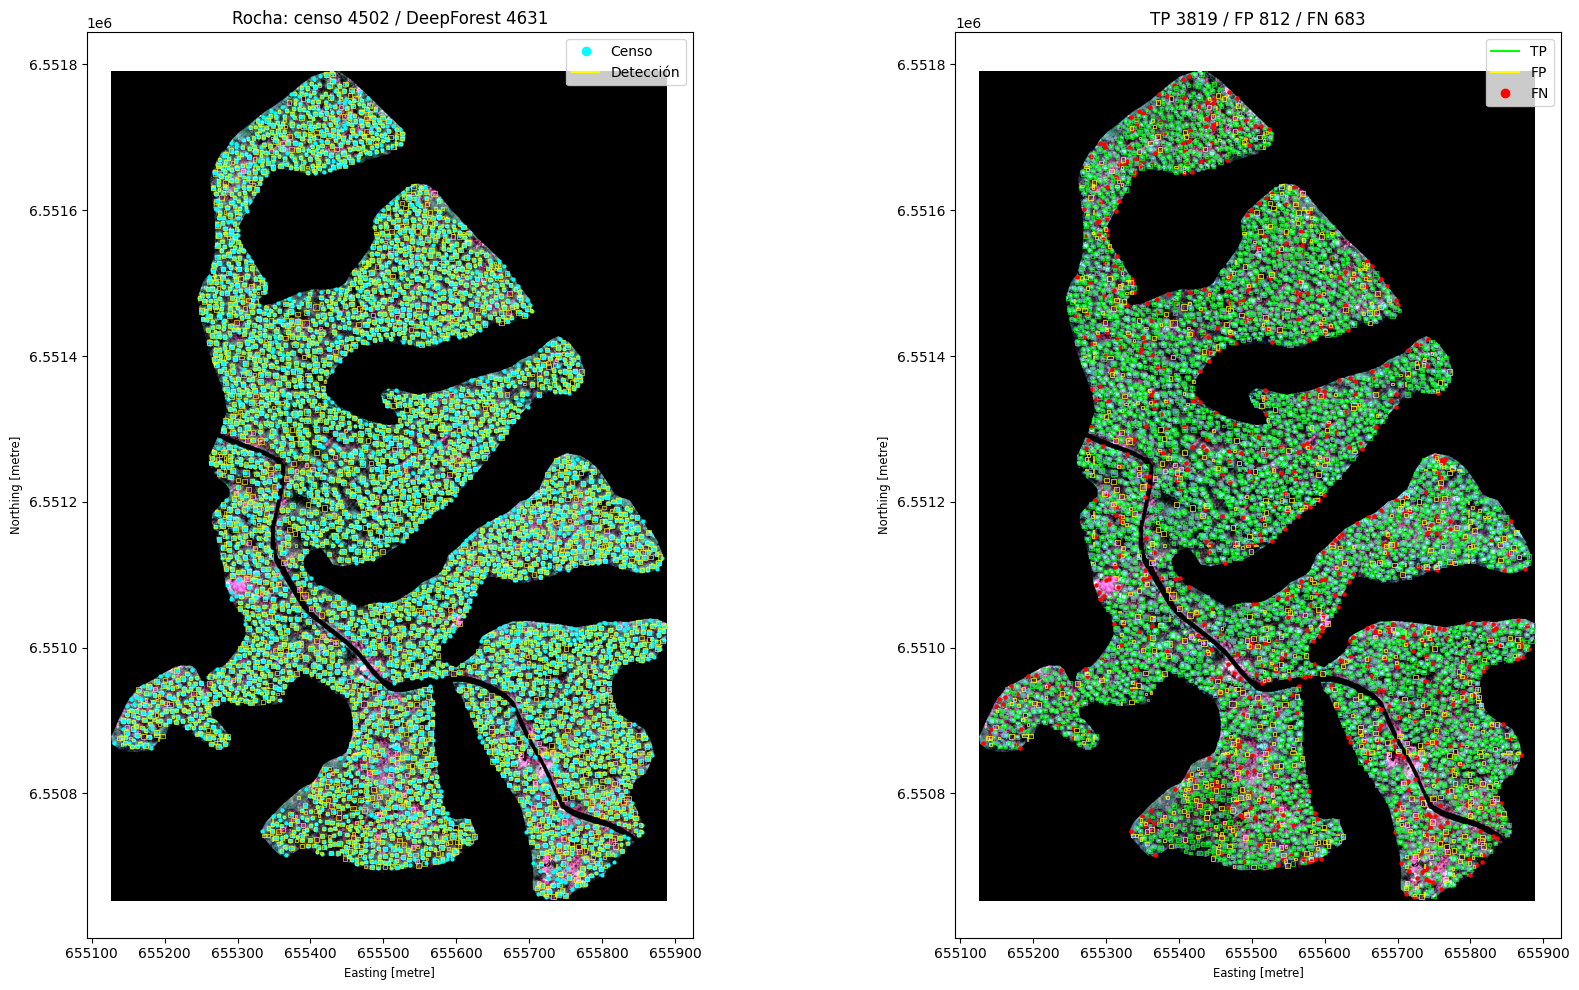

Mapa: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/resultados/Rocha_DeepForest/DeepForest_mapa_evaluacion.png


In [13]:
# Representar las detecciones correctas, adicionales y omitidas.
ids_ref={r['id_punto'] for r in coincidencias}
ids_pred={r['id_pred'] for r in coincidencias}
fn=ref.loc[~ref.id_punto.isin(ids_ref)]
fp=pred_eval.loc[~pred_eval.id_pred.isin(ids_pred)]
tp=pred_eval.loc[pred_eval.id_pred.isin(ids_pred)]
with rasterio.open(PREPARADA) as src:
    escala=max(1,int(np.ceil(max(src.width,src.height)/2000)))
    img=src.read([1,2,3],out_shape=(3,max(1,src.height//escala),max(1,src.width//escala)),resampling=Resampling.nearest)
    rgb=np.moveaxis(img,0,-1)
    b=src.bounds
fig,axes=plt.subplots(1,2,figsize=(18,10))
for ax in axes:
    ax.imshow(rgb,extent=(b.left,b.right,b.bottom,b.top),origin='upper')
    ax.set_aspect('equal')
if len(pred_eval):pred_eval.boundary.plot(ax=axes[0],color='yellow',linewidth=.45)
ref.plot(ax=axes[0],color='cyan',markersize=4)
axes[0].set_title(f'{SITIO}: censo {NR} / DeepForest {NP}')
axes[0].legend(handles=[Line2D([0],[0],marker='o',linestyle='',color='cyan',label='Censo'),Line2D([0],[0],color='yellow',label='Detección')])
if len(tp):tp.boundary.plot(ax=axes[1],color='lime',linewidth=.5)
if len(fp):fp.boundary.plot(ax=axes[1],color='yellow',linewidth=.5)
if len(fn):fn.plot(ax=axes[1],color='red',markersize=5)
axes[1].set_title(f'TP {TP} / FP {FP} / FN {FN}')
axes[1].legend(handles=[Line2D([0],[0],color='lime',label='TP'),Line2D([0],[0],color='yellow',label='FP'),Line2D([0],[0],marker='o',linestyle='',color='red',label='FN')])
# Zoom a la zona de evaluación, no a toda la extensión de la ortofoto.
x0,y0,x1,y1=ref.total_bounds
mx=(x1-x0)*.05;my=(y1-y0)*.05
for ax in axes:
    ax.set_xlim(x0-mx,x1+mx);ax.set_ylim(y0-my,y1+my)
fig.tight_layout()
fig.savefig(SALIDA/'DeepForest_mapa_evaluacion.png',dpi=250,bbox_inches='tight')
plt.show()
plt.close(fig)
print('Mapa:',SALIDA/'DeepForest_mapa_evaluacion.png')

En el establecimiento Rocha, el modelo DeepForest fue evaluado mediante la detección individual de árboles sobre una ortofoto y su posterior correspondencia espacial con los registros censales. De los 4.844 árboles del censo de referencia, 4.502 resultaron evaluables tras aplicar la máscara de cobertura válida. El modelo generó 4.631 detecciones, de las cuales 3.819 correspondieron a verdaderos positivos y 812 a falsos positivos, mientras que 683 árboles censados no fueron detectados.

A partir de estos resultados, se obtuvo una precisión del 82,47 %, un recall del 84,83 % y un F1-score del 83,63 %. En cuanto al conteo, el modelo presentó una sobreestimación neta de 129 árboles, equivalente a un error porcentual del +2,87 %.

Estos resultados evidencian un buen desempeño en la detección individual de árboles, con un equilibrio favorable entre precisión y recall. Si bien el conteo total se aproxima al valor censal, persisten tanto detecciones sin correspondencia como árboles omitidos, lo que demuestra que un error de conteo reducido no implica necesariamente una identificación individual correcta de todos los árboles.

### Experimento adicional: DeepForest en escala de grises

Se utiliza la misma máscara y el mismo censo evaluable que en RGB.

In [17]:
# Crear una imagen de tres canales en escala de grises, conservando la máscara válida.
from pathlib import Path
import numpy as np
import rasterio
from tqdm.auto import tqdm

SALIDA_GRISES = (
    Path(SALIDA) / "experimento_escala_grises"
)
SALIDA_GRISES.mkdir(parents=True, exist_ok=True)

RASTER_GRISES = SALIDA_GRISES / "Rocha_grises_3canales.tif"

with rasterio.open(PREPARADA) as src, \
     rasterio.open(MASCARA) as msk:

    assert src.width == msk.width
    assert src.height == msk.height
    assert src.transform == msk.transform
    assert src.crs == msk.crs

    perfil = src.profile.copy()
    perfil.update(
        driver="GTiff",
        count=3,
        dtype="uint8",
        nodata=0,
        compress="deflate"
    )

    with rasterio.open(RASTER_GRISES, "w", **perfil) as dst:

        for _, win in tqdm(
            src.block_windows(1),
            desc="Aplicar escala de grises"
        ):

            rgb = src.read([1, 2, 3], window=win)
            valido = msk.read(1, window=win) == 1

            # Luminancia RGB (BT.601)
            gris = (
                0.299 * rgb[0].astype(np.float32)
                + 0.587 * rgb[1].astype(np.float32)
                + 0.114 * rgb[2].astype(np.float32)
            )

            gris = np.clip(
                np.rint(gris), 0, 255
            ).astype(np.uint8)

            gris[~valido] = 0

            gris_3 = np.repeat(
                gris[np.newaxis, :, :],
                3,
                axis=0
            )

            dst.write(gris_3, window=win)

print("Imagen gris creada:", RASTER_GRISES)

Aplicar escala de grises: 0it [00:00, ?it/s]

Imagen gris creada: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/resultados/Rocha_DeepForest/experimento_escala_grises/Rocha_grises_3canales.tif


In [18]:
# Ejecutar DeepForest sobre la imagen en escala de grises.
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from shapely.geometry import box
from deepforest import main

PATCH_GRISES = 400
OVERLAP_GRISES = 0.30
SCORE_GRISES = 0.15
IOU_GRISES = 0.15

modelo_grises = main.deepforest()
modelo_grises.load_model(
    model_name="weecology/deepforest-tree"
)

predicciones_grises = modelo_grises.predict_tile(
    path=str(RASTER_GRISES),
    patch_size=PATCH_GRISES,
    patch_overlap=OVERLAP_GRISES,
    iou_threshold=IOU_GRISES
)

if predicciones_grises is None or len(predicciones_grises) == 0:
    predicciones_grises = pd.DataFrame(
        columns=["xmin", "ymin", "xmax", "ymax", "score"]
    )
else:
    predicciones_grises = (
        predicciones_grises.loc[
            predicciones_grises["score"] >= SCORE_GRISES
        ]
        .copy()
        .reset_index(drop=True)
    )

# Convertir las cajas de píxeles a geometrías geográficas
with rasterio.open(RASTER_GRISES) as src:
    transformacion = src.transform
    crs_grises = src.crs

geometrias_grises = []

for r in predicciones_grises.itertuples():
    x1, y1 = rasterio.transform.xy(
        transformacion, r.ymin, r.xmin, offset="ul"
    )
    x2, y2 = rasterio.transform.xy(
        transformacion, r.ymax, r.xmax, offset="ul"
    )

    geometrias_grises.append(
        box(
            min(x1, x2), min(y1, y2),
            max(x1, x2), max(y1, y2)
        )
    )

pred_grises = gpd.GeoDataFrame(
    predicciones_grises.copy(),
    geometry=geometrias_grises,
    crs=crs_grises
)

print("Detecciones antes de máscara:", len(pred_grises))

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


4185 predictions in overlapping windows, applying non-max suppression
2338 predictions kept after non-max suppression
Detecciones antes de máscara: 1428


In [19]:
ref_grises, pred_eval_grises, coincidencias_grises, metricas_grises = evaluar_detecciones(pred_grises, censo_eval, MASCARA_COMUN)
resumen_grises = pd.DataFrame([dict(sitio=SITIO, modelo='DeepForest (grises)', **metricas_grises)])
display(resumen_grises.round(4))
resumen_grises.to_csv(SALIDA_GRISES / 'metricas_grises.csv', index=False)
comparacion_grises = pd.concat([resumen_deepforest, resumen_grises], ignore_index=True)
display(comparacion_grises[['modelo','censo_evaluable','detecciones','precision','recall','F1','error_conteo_pct']].round(4))

,sitio,modelo,censo_total,censo_evaluable,detecciones,TP,FP,FN,precision,recall,F1,error_conteo_pct,error_absoluto_pct
0,Rocha,DeepForest (grises),4844,4502,1370,842,528,3660,0.6146,0.187,0.2868,-69.5691,69.5691


,modelo,censo_evaluable,detecciones,precision,recall,F1,error_conteo_pct
0,DeepForest,4502,4631,0.8247,0.8483,0.8363,2.8654
1,DeepForest (grises),4502,1370,0.6146,0.1870,0.2868,-69.5691


## 4. Mask R-CNN

### Configuración

In [20]:
MODELO='Mask_RCNN'


SALIDA = PROYECTO / 'PruebaFinal' / 'resultados' / SITIO / MODELO
SALIDA.mkdir(parents=True, exist_ok=True)

print('Sitio:', SITIO, '| Modelo:', MODELO)
print('Imagen:', RASTER)
print('Censo:', CENSO)
print('Salida:', SALIDA)
MASCARA = MASCARA_COMUN

TILE = 640
STRIDE = 512
CONF = 0.20
MASK_THR = 0.50
MIN_PIX = 15
MIN_VALID_FRAC = 0.10
NMS_IOU = 0.50


Sitio: Rocha | Modelo: Mask_RCNN
Imagen: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/datos/Rocha_20240222_censo_clip.tif
Censo: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/datos/Censo_Rocha_parcelas_15-16.shp
Salida: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/resultados/Rocha/Mask_RCNN


### Inferencia y eliminación de duplicados

In [21]:
# Preparar RGB y ejecutar Mask R-CNN por teselas, con NMS para quitar duplicados.
from pathlib import Path
import rasterio
import numpy as np

RASTER_MODELO = RASTER

with rasterio.open(RASTER_MODELO) as src, rasterio.open(MASCARA) as msk:

    assert src.width == msk.width
    assert src.height == msk.height
    assert src.transform == msk.transform
    assert src.crs == msk.crs

    # Bandas RGB
    rgb = src.read([1, 2, 3])
    rgb = np.moveaxis(rgb, 0, -1).astype(np.uint8)

    # Máscara válida generada desde el canal alfa
    valido = msk.read(1) == 1

    # Ocultar zonas sin cobertura
    rgb[~valido] = 0

print("Dimensiones:", rgb.shape)
print("Tipo de dato:", rgb.dtype)
print("Cobertura válida (%):", round(100 * valido.mean(), 2))
from pathlib import Path
import numpy as np
import geopandas as gpd
import rasterio
import torch

from rasterio.windows import Window
from rasterio.features import shapes
from shapely.geometry import shape
from tqdm.auto import tqdm

from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor


MASCARA = Path(MASCARA)

censo_eval = censo_eval.copy().reset_index(drop=True)

#Parámetros de inferencia
TILE = 640
STRIDE = 512
CONF = 0.20
MASK_THR = 0.50
MIN_PIX = 15
NMS_IOU = 0.50
MIN_VALID_FRAC = 0.10

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

#Cargar modelo entrenado

PESOS = (
    PROYECTO
    / "MASK-R-CNN"
    / "runs"
    / "mask_rcnn_R50_FPN_torchvision"
    / "maskrcnn_final.pth"
)


modelo = maskrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=None
)

n_features = (
    modelo.roi_heads.box_predictor.cls_score.in_features
)

modelo.roi_heads.box_predictor = FastRCNNPredictor(
    n_features, 2
)

n_features_mask = (
    modelo.roi_heads.mask_predictor.conv5_mask.in_channels
)

modelo.roi_heads.mask_predictor = MaskRCNNPredictor(
    n_features_mask, 256, 2
)

estado = torch.load(
    PESOS,
    map_location="cpu",
    weights_only=True
)

modelo.load_state_dict(estado, strict=True)
modelo.to(DEVICE).eval()

print("Pesos:", PESOS)
print("Dispositivo:", DEVICE)
print("Árboles censados evaluables:", len(censo_eval))

# Función para generar posiciones de teselas

def posiciones_tiles(total, tam, paso):
    if total <= tam:
        return [0]

    posiciones = list(range(0, total - tam + 1, paso))

    if posiciones[-1] != total - tam:
        posiciones.append(total - tam)

    return sorted(set(posiciones))

# Recorrer la ortofoto y detectar copas

registros = []
tiles_procesados = 0
tiles_saltados = 0

with rasterio.open(RASTER_MODELO) as src, \
     rasterio.open(MASCARA) as msk:

    # Confirmar correspondencia espacial
    assert src.width == msk.width
    assert src.height == msk.height
    assert src.transform == msk.transform
    assert src.crs == msk.crs
    assert src.crs == censo_eval.crs

    assert src.count >= 3, (
        "La ortofoto debe tener al menos tres bandas RGB."
    )

    xs = posiciones_tiles(src.width, TILE, STRIDE)
    ys = posiciones_tiles(src.height, TILE, STRIDE)

    print("\nTeselas totales:", len(xs) * len(ys))

    for y in tqdm(ys, desc="Inferencia Mask R-CNN"):

        for x in xs:

            w = min(TILE, src.width - x)
            h = min(TILE, src.height - y)

            ventana = Window(x, y, w, h)

            # RGB original
            imagen = src.read(
                [1, 2, 3],
                window=ventana
            )

            rgb = np.moveaxis(
                imagen, 0, -1
            ).astype(np.uint8)

            # Máscara alfa previamente generada
            valido = (
                msk.read(1, window=ventana) == 1
            )

            fraccion_valida = float(valido.mean())

            if fraccion_valida < MIN_VALID_FRAC:
                tiles_saltados += 1
                continue

            # Anular píxeles sin cobertura
            rgb[~valido] = 0

            # Convertir imagen RGB a tensor
            tensor = (
                torch.from_numpy(
                    np.ascontiguousarray(rgb)
                )
                .permute(2, 0, 1)
                .float()
                .div(255.0)
                .to(DEVICE)
            )

            # Inferencia, sin modificar pesos
            with torch.inference_mode():
                salida = modelo([tensor])[0]

            # Extraer predicciones
            scores = (
                salida["scores"]
                .detach().cpu().numpy()
            )

            labels = (
                salida["labels"]
                .detach().cpu().numpy()
            )

            mascaras = (
                salida["masks"]
                .detach().cpu().numpy()
            )

            transformacion = src.window_transform(ventana)

            for score, label, mascara_pred in zip(
                scores, labels, mascaras
            ):

                if int(label) != 1:
                    continue

                if float(score) < CONF:
                    continue

                binaria = (
                    mascara_pred[0] >= MASK_THR
                )

                # Excluir partes transparentes
                binaria[~valido] = False

                if int(binaria.sum()) < MIN_PIX:
                    continue

                # Convertir máscaras a polígonos
                for geometria, valor in shapes(
                    binaria.astype("uint8"),
                    mask=binaria,
                    transform=transformacion
                ):

                    if valor != 1:
                        continue

                    poligono = shape(geometria)

                    if poligono.is_empty:
                        continue

                    if not poligono.is_valid:
                        poligono = poligono.buffer(0)

                    if poligono.is_empty:
                        continue

                    registros.append({
                        "score": float(score),
                        "geometry": poligono
                    })

            tiles_procesados += 1

            del tensor, salida, scores, labels, mascaras

print("\nRESUMEN DE INFERENCIA")
print("Teselas procesadas:", tiles_procesados)
print("Teselas saltadas:", tiles_saltados)
print("Propuestas crudas:", len(registros))

#Crear GeoDataFrame de predicciones crudas

pred_brutas = gpd.GeoDataFrame(
    registros,
    columns=["score", "geometry"],
    geometry="geometry",
    crs=censo_eval.crs
)

pred_brutas = pred_brutas.sort_values(
    "score",
    ascending=False
).reset_index(drop=True)

#Eliminar duplicados por IoU
guardados = []
guardados_set = set()

if len(pred_brutas) > 0:

    indice_espacial = pred_brutas.sindex

    for i in tqdm(
        range(len(pred_brutas)),
        desc="Eliminando duplicados"
    ):

        geom_i = pred_brutas.geometry.iloc[i]

        duplicado = False

        candidatos = indice_espacial.query(
            geom_i,
            predicate="intersects"
        )

        for j in candidatos:

            j = int(j)

            # Comparar solo con detecciones conservadas
            if j not in guardados_set:
                continue

            geom_j = pred_brutas.geometry.iloc[j]

            inter = geom_i.intersection(geom_j).area
            union = geom_i.union(geom_j).area

            if union <= 0:
                continue

            iou = inter / union

            if iou >= NMS_IOU:
                duplicado = True
                break

        if not duplicado:
            guardados.append(i)
            guardados_set.add(i)

pred_unicas = (
    pred_brutas.iloc[guardados]
    .copy()
    .reset_index(drop=True)
)

print("\nRESULTADO DE DEDUPLICACIÓN")
print("Propuestas crudas:", len(pred_brutas))
print("Detecciones únicas:", len(pred_unicas))
print("Duplicados eliminados:",
      len(pred_brutas) - len(pred_unicas))

Dimensiones: (4909, 3291, 3)
Tipo de dato: uint8
Cobertura válida (%): 43.12
Pesos: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/MASK-R-CNN/runs/mask_rcnn_R50_FPN_torchvision/maskrcnn_final.pth
Dispositivo: cuda
Árboles censados evaluables: 4502

Teselas totales: 70


Inferencia Mask R-CNN:   0%|          | 0/10 [00:00<?, ?it/s]


RESUMEN DE INFERENCIA
Teselas procesadas: 55
Teselas saltadas: 15
Propuestas crudas: 5242


Eliminando duplicados:   0%|          | 0/5242 [00:00<?, ?it/s]


RESULTADO DE DEDUPLICACIÓN
Propuestas crudas: 5242
Detecciones únicas: 3288
Duplicados eliminados: 1954


### Evaluación

In [22]:
ref, pred_eval, coincidencias, metricas = evaluar_detecciones(pred_unicas, censo_eval, MASCARA)
NR, NP = metricas['censo_evaluable'], metricas['detecciones']
TP, FP, FN = metricas['TP'], metricas['FP'], metricas['FN']
resumen = pd.DataFrame([dict(sitio=SITIO, modelo='Mask R-CNN R50-FPN', **metricas)])
resumen_mask_rcnn = resumen.copy()
display(resumen.round(4))
resumen.to_csv(SALIDA / 'Mask_RCNN_metricas.csv', index=False)
pd.DataFrame(coincidencias, columns=['id_punto','id_pred','distancia_m']).to_csv(SALIDA / 'Mask_RCNN_coincidencias.csv', index=False)
ref.to_file(SALIDA / 'censo_evaluable.gpkg', driver='GPKG')
if len(pred_eval):
    pred_eval.to_file(SALIDA / 'detecciones_evaluables.gpkg', driver='GPKG')

# Alias usados en los mapas originales de Rocha.
N_REAL, N_PRED = NR, NP
precision, recall, f1 = metricas['precision'], metricas['recall'], metricas['F1']


,sitio,modelo,censo_total,censo_evaluable,detecciones,TP,FP,FN,precision,recall,F1,error_conteo_pct,error_absoluto_pct
0,Rocha,Mask R-CNN R50-FPN,4844,4502,3288,2953,335,1549,0.8981,0.6559,0.7582,-26.9658,26.9658


### Visualización

In [23]:
# Visualizar el censo, las detecciones y los errores TP / FP / FN.

import numpy as np
import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd
import pandas as pd

from matplotlib.lines import Line2D
from pathlib import Path

ref_mapa = ref.copy().reset_index(drop=True)
pred_mapa = pred_eval.copy().reset_index(drop=True)

#Preparar imagen RGB de fondo
with rasterio.open(RASTER_MODELO) as src:

    # Imagen reducida solo para visualización
    factor = max(
        1,
        int(np.ceil(max(src.width, src.height) / 1800))
    )

    rgb = src.read(
        [1, 2, 3],
        out_shape=(
            3,
            max(1, src.height // factor),
            max(1, src.width // factor)
        )
    )

    rgb = np.moveaxis(rgb, 0, -1).astype(np.uint8)

    bounds = src.bounds
    crs_raster = src.crs

# Asegurar el mismo sistema de coordenadas
if ref_mapa.crs != crs_raster:
    ref_mapa = ref_mapa.to_crs(crs_raster)

if pred_mapa.crs != crs_raster:
    pred_mapa = pred_mapa.to_crs(crs_raster)

extension = (
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
)

# Censo vs mask r-cnn
fig, ax = plt.subplots(figsize=(11, 13))

ax.imshow(
    rgb,
    extent=extension,
    origin="upper"
)

if len(pred_mapa):
    pred_mapa.boundary.plot(
        ax=ax,
        color="yellow",
        linewidth=0.65
    )

ref_mapa.plot(
    ax=ax,
    color="cyan",
    markersize=5
)

leyenda_general = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="none",
        markerfacecolor="cyan",
        markeredgecolor="cyan",
        markersize=7,
        label="Árboles censados evaluables"
    ),
    Line2D(
        [0], [0],
        color="yellow",
        linewidth=2,
        label="Copas detectadas por Mask R-CNN"
    )
]

ax.legend(
    handles=leyenda_general,
    loc="upper right",
    fontsize=9
)

ax.set_title(
    "Mask R-CNN — Rocha\n"
    f"Censo evaluable: {N_REAL} | "
    f"Detecciones: {N_PRED}",
    fontsize=13
)

ax.set_xlabel("Coordenada X")
ax.set_ylabel("Coordenada Y")

plt.tight_layout()

ruta_general = (
    SALIDA / "Rocha_Mask_RCNN_mapa_general.png"
)

fig.savefig(
    ruta_general,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Mapa general guardado:", ruta_general)

#Clasificar TP, FP y FN
coincidencias_df = pd.DataFrame(
    coincidencias,
    columns=["id_punto", "id_pred", "distancia_m"]
)

ids_ref_tp = set(
    coincidencias_df["id_punto"].astype(int)
)

ids_pred_tp = set(
    coincidencias_df["id_pred"].astype(int)
)

tp_pred = pred_mapa[
    pred_mapa["id_pred"].isin(ids_pred_tp)
].copy()

fp_pred = pred_mapa[
    ~pred_mapa["id_pred"].isin(ids_pred_tp)
].copy()

fn_ref = ref_mapa[
    ~ref_mapa["id_punto"].isin(ids_ref_tp)
].copy()


print("\nCONTROL DEL MAPA")
print("TP:", len(tp_pred))
print("FP:", len(fp_pred))
print("FN:", len(fn_ref))

#Mapa de TP, FP Y FN
fig, ax = plt.subplots(figsize=(11, 13))

ax.imshow(
    rgb,
    extent=extension,
    origin="upper"
)

# Verdaderos positivos: copas detectadas
if len(tp_pred):
    tp_pred.boundary.plot(
        ax=ax,
        color="lime",
        linewidth=0.75
    )

# Falsos positivos: copas sin asociación con censo
if len(fp_pred):
    fp_pred.boundary.plot(
        ax=ax,
        color="yellow",
        linewidth=0.9
    )

# Falsos negativos: árboles censados no detectados
if len(fn_ref):
    fn_ref.plot(
        ax=ax,
        color="red",
        markersize=9
    )

leyenda_errores = [
    Line2D(
        [0], [0],
        color="lime",
        linewidth=2,
        label=f"TP: {TP}"
    ),
    Line2D(
        [0], [0],
        color="yellow",
        linewidth=2,
        label=f"FP: {FP}"
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="none",
        markerfacecolor="red",
        markeredgecolor="red",
        markersize=7,
        label=f"FN: {FN}"
    )
]

ax.legend(
    handles=leyenda_errores,
    loc="upper right",
    fontsize=9
)

ax.set_title(
    "Mask R-CNN — Evaluación censal en Rocha\n"
    f"Precisión: {precision:.2%} | "
    f"Recall: {recall:.2%} | "
    f"F1: {f1:.2%}",
    fontsize=13
)

ax.set_xlabel("Coordenada X")
ax.set_ylabel("Coordenada Y")

plt.tight_layout()

ruta_errores = (
    SALIDA / "Rocha_Mask_RCNN_TP_FP_FN.png"
)

fig.savefig(
    ruta_errores,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Mapa TP/FP/FN guardado:", ruta_errores)

Output hidden; open in https://colab.research.google.com to view.

En el establecimiento Rocha, el modelo Mask R-CNN con arquitectura ResNet-50 y Feature Pyramid Network (R50-FPN) fue evaluado mediante la detección y segmentación de copas individuales sobre una ortofoto y su posterior correspondencia espacial con los registros censales. De los 4.844 árboles del censo de referencia, 4.502 resultaron evaluables tras aplicar la máscara de cobertura válida. El modelo generó 3.288 detecciones, de las cuales 2.953 correspondieron a verdaderos positivos y 335 a falsos positivos, mientras que 1.549 árboles censados no fueron detectados.

A partir de estos resultados, se obtuvo una precisión del 89,81 %, un recall del 65,59 % y un F1-score del 75,82 %. En cuanto al conteo, el modelo presentó una subestimación neta de 1.214 árboles, equivalente a un error porcentual del −26,97 %.

Estos resultados evidencian una elevada precisión en las detecciones realizadas, aunque con una capacidad de recuperación de árboles considerablemente menor. Si bien la mayoría de las detecciones generadas presentan correspondencia con el censo, la cantidad de árboles omitidos afecta tanto el desempeño global del modelo como la estimación del número total de individuos.

## 5. Comparación final

In [24]:
columnas = ['sitio','modelo','censo_evaluable','detecciones','TP','FP','FN','precision','recall','F1','error_conteo_pct']
comparacion = pd.concat([resumen_deepforest, resumen_mask_rcnn, resumen_grises], ignore_index=True)
display(comparacion[columnas].round(4))
comparacion.to_csv(SALIDA_COMUN / 'comparacion_modelos.csv', index=False)

,sitio,modelo,censo_evaluable,detecciones,TP,FP,FN,precision,recall,F1,error_conteo_pct
0,Rocha,DeepForest,4502,4631,3819,812,683,0.8247,0.8483,0.8363,2.8654
1,Rocha,Mask R-CNN R50-FPN,4502,3288,2953,335,1549,0.8981,0.6559,0.7582,-26.9658
2,Rocha,DeepForest (grises),4502,1370,842,528,3660,0.6146,0.1870,0.2868,-69.5691
